# A1-1 쇼핑몰 단골 찾기 — 분석 리포트

H&M Personalized Fashion Recommendations(Kaggle) 데이터로 멀티모달 EDA 와 RFM 고객 세분화를 한다.
분석 로직은 `src/pipeline.py` 의 `DataAnalyzer` 클래스에 있고, 이 노트북은 그 결과를 읽고 해석한다.

In [1]:
import sys
from pathlib import Path

# 노트북은 notebooks/ 에서 실행되므로 프로젝트 루트를 import 경로에 넣는다
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src.pipeline import DataAnalyzer, correlation_pairs, summary_stats

pd.set_option("display.max_columns", 30)

## 1. 데이터 로드 및 기본 탐색

### 표본 기준

| 항목 | 기준 |
|---|---|
| 기간 | 2019-09-23 ~ 2020-09-22 (최근 12개월) |
| 고객 | 기간 안에 1번 이상 산 고객 중 무작위 1만 명 (`random_state=42`) |
| 거래 | 뽑힌 고객의 기간 내 거래 줄 **전부** — 줄을 뽑으면 고객마다 F·M 이 줄어든다 |
| 결합 | 거래 줄마다 상품(`articles`)·고객(`customers`) 정보를 왼쪽 결합 |
| Recency 기준일 | 2020-09-22 (데이터 마지막 거래일) |

In [2]:
analyzer = DataAnalyzer()
df = analyzer.load_data()
analyzer.load_summary

{'start_date': '2019-09-23',
 'end_date': '2020-09-22',
 'random_state': 42,
 'rows_read': 31788324,
 'window_rows': 14898423,
 'window_customers': 994320,
 'sampled_customers': 10000,
 'rows': 149548,
 'articles_unmatched': 0,
 'customers_unmatched': 0,
 'seconds': 8.8}

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149548 entries, 0 to 149547
Data columns (total 23 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   t_dat                         149548 non-null  datetime64[us]
 1   customer_id                   149548 non-null  str           
 2   article_id                    149548 non-null  int64         
 3   price                         149548 non-null  float64       
 4   sales_channel_id              149548 non-null  int8          
 5   prod_name                     149548 non-null  str           
 6   product_type_name             149548 non-null  str           
 7   product_group_name            149548 non-null  str           
 8   graphical_appearance_name     149548 non-null  str           
 9   colour_group_name             149548 non-null  str           
 10  perceived_colour_value_name   149548 non-null  str           
 11  perceived_colour_master_

**해석 — 구조와 결측**

- 149,548줄 × 23열로 과제 기준(1,000건·8열)을 넘는다. 날짜형(`t_dat`)·수치형(`price`·`age`)·범주형(`product_type_name` 등 11열)·텍스트(`prod_name`·`detail_desc`)가 있고, 이미지는 사진 확보 후 붙인다.
- 결측은 고객 정보에 몰려 있다: `FN` 83,493줄(55.8%)·`Active` 84,122줄(56.3%), `fashion_news_frequency` 671줄, `age` 431줄(0.3%), `club_member_status` 279줄, `detail_desc` 157줄.
- **시사점**: 절반 넘게 빈 열은 대치하기 전에 빈칸이 무슨 뜻인지부터 확인해야 한다.

In [4]:
df.describe()

,t_dat,article_id,price,sales_channel_id,FN,Active,age
count,149548,1.495480e+05,149548.000000,149548.000000,66055.0,65426.0,149117.000000
mean,2020-03-29 11:49:18.129831,7.526006e+08,0.028009,1.714125,1.0,1.0,35.532468
min,2019-09-23 00:00:00,1.087750e+08,0.000424,1.000000,1.0,1.0,17.000000
25%,2019-12-24 00:00:00,7.060160e+08,0.016542,1.000000,1.0,1.0,25.000000
50%,2020-04-09 00:00:00,7.872255e+08,0.025407,2.000000,1.0,1.0,31.000000
75%,2020-06-26 00:00:00,8.362840e+08,0.033881,2.000000,1.0,1.0,47.000000
max,2020-09-22 00:00:00,9.534500e+08,0.422034,2.000000,1.0,1.0,99.000000
std,NaN,1.302270e+08,0.019107,0.451832,0.0,0.0,13.358036


**해석 — 수치형 분포**

- `price` 는 평균 0.0280 > 중앙값 0.0254 이고, 최댓값 0.4220 이 Q3(0.0339)의 약 12배다 → 오른쪽 꼬리가 긴 분포.
- `age` 는 중앙값 31세, Q1 25 ~ Q3 47. 단 이 표는 **거래 줄 기준**이라 자주 사는 고객의 나이가 여러 번 세어진다.
- `FN`·`Active` 는 값이 있는 줄이 전부 1.0(std 0)이다.
- **시사점**: 금액도 소수에 쏠릴 수 있어 이상치 처리 전후 비교가 필요하고, 고객 특성은 고객 단위로 묶어 다시 봐야 한다.

In [5]:
df.describe(include="str")

,customer_id,prod_name,product_type_name,product_group_name,graphical_appearance_name,colour_group_name,perceived_colour_value_name,perceived_colour_master_name,department_name,index_name,index_group_name,section_name,garment_group_name,detail_desc,club_member_status,fashion_news_frequency
count,149548,149548,149548,149548,149548,149548,149548,149548,149548,149548,149548,149548,149548,149391,149269,148877
unique,10000,14685,110,15,29,50,8,19,230,10,5,55,21,13737,3,2
top,92838b6470bf09ea2247a7f244a059e13eec4224cfe93d...,Jade HW Skinny Denim TRS,Trousers,Garment Upper body,Solid,Black,Dark,Black,Swimwear,Ladieswear,Ladieswear,Womens Everyday Collection,Jersey Fancy,High-waisted jeans in washed superstretch deni...,ACTIVE,NONE
freq,462,1089,19771,57944,88522,51990,70672,51874,10747,62482,98193,28172,23342,1155,147015,82504


**해석 — 범주형·식별자**

- `customer_id` 고유값 10,000 = 뽑은 고객 수. 고객당 평균 15.0줄인데 최다 고객은 462줄로 약 31배다.
- `index_group_name` 5개 중 Ladieswear 가 98,193줄(65.7%), `product_type_name` 110종 중 Trousers 가 19,771줄(13.2%)로 가장 많다.
- **시사점**: RFM 에서 극단적인 고객을 어떻게 다룰지 정해야 하고, 세그먼트 전략은 여성복 중심으로 해석된다.

In [6]:
df.head()

,t_dat,customer_id,article_id,price,sales_channel_id,prod_name,product_type_name,product_group_name,graphical_appearance_name,colour_group_name,perceived_colour_value_name,perceived_colour_master_name,department_name,index_name,index_group_name,section_name,garment_group_name,detail_desc,FN,Active,club_member_status,fashion_news_frequency,age
0,2019-09-23,04e2301dc0581c5b443429e1614cf21ffe9b23d8d3fe05...,740943002,0.013542,2,Pamela,Dress,Garment Full body,Stripe,Off White,Dusty Light,White,Dress,Ladieswear,Ladieswear,Womens Everyday Collection,Dresses Ladies,Short dress in a viscose weave with a gentle V...,1.0,1.0,ACTIVE,Regularly,34.0
1,2019-09-23,04e2301dc0581c5b443429e1614cf21ffe9b23d8d3fe05...,660497001,0.018627,2,Emery(1),Dress,Garment Full body,Solid,Black,Dark,Black,Jersey fancy,Ladieswear,Ladieswear,Womens Everyday Collection,Jersey Fancy,Short sleeveless dress in soft slub jersey mad...,1.0,1.0,ACTIVE,Regularly,34.0
2,2019-09-23,04e2301dc0581c5b443429e1614cf21ffe9b23d8d3fe05...,727611003,0.025407,2,Zidane jumpsuit,Jumpsuit/Playsuit,Garment Full body,All over pattern,Yellow,Medium,Yellow,Dresses,Divided,Divided,Divided Collection,Dresses Ladies,V-neck playsuit in a crinkled weave with a wra...,1.0,1.0,ACTIVE,Regularly,34.0
3,2019-09-23,04e2301dc0581c5b443429e1614cf21ffe9b23d8d3fe05...,727611003,0.025407,2,Zidane jumpsuit,Jumpsuit/Playsuit,Garment Full body,All over pattern,Yellow,Medium,Yellow,Dresses,Divided,Divided,Divided Collection,Dresses Ladies,V-neck playsuit in a crinkled weave with a wra...,1.0,1.0,ACTIVE,Regularly,34.0
4,2019-09-23,04e2301dc0581c5b443429e1614cf21ffe9b23d8d3fe05...,740943001,0.013542,2,Pamela,Dress,Garment Full body,All over pattern,Dark Orange,Dark,Beige,Dress,Ladieswear,Ladieswear,Womens Everyday Collection,Dresses Ladies,Short dress in a viscose weave with a gentle V...,1.0,1.0,ACTIVE,Regularly,34.0


**해석 — 실제 줄 모양**

- 인덱스 2·3 은 같은 고객·같은 날·같은 상품(`727611003`)·같은 가격이다. Kaggle 데이터 설명대로 **같은 상품을 2개 산 것**을 뜻하는 중복 줄이다(이 데이터에는 수량 열이 없다).
- 다섯 줄 모두 같은 고객·같은 날이라, 주문 정의(고객 + 날짜)로는 주문 1건이다.
- **시사점**: 중복 줄을 지우면 M(금액)이 줄어들므로 지우지 않는다.

## 2. 멀티모달 피처 엔지니어링

### 2-1. 텍스트 — 상품명 단어 수·글자 수

`add_text_features()` 가 `prod_name` 에서 `prod_name_word_count`(공백 기준 단어 수)와 `prod_name_length`(글자 수)를 만든다. `.str` 접근자로 열 전체를 한 번에 계산한다.

In [7]:
analyzer.add_text_features()
df[["prod_name", "prod_name_word_count", "prod_name_length"]].head()

,prod_name,prod_name_word_count,prod_name_length
0,Pamela,1,6
1,Emery(1),1,8
2,Zidane jumpsuit,2,15
3,Zidane jumpsuit,2,15
4,Pamela,1,6


In [8]:
# 상품명은 상품의 속성이므로 상품 1개당 1번만 세어 분포를 본다 (거래 줄 기준이면 많이 팔린 상품이 여러 번 세어짐)
products = df.drop_duplicates("article_id")
print("고유 상품 수:", len(products))
products[["prod_name_word_count", "prod_name_length"]].describe()

고유 상품 수: 27783


,prod_name_word_count,prod_name_length
count,27783.000000,27783.000000
mean,2.794947,15.776122
std,1.041518,5.808003
min,1.000000,1.000000
25%,2.000000,12.000000
50%,3.000000,15.000000
75%,3.000000,20.000000
max,7.000000,30.000000


In [9]:
products["prod_name_word_count"].value_counts().sort_index()

prod_name_word_count
1    2351
2    9366
3    9546
4    4890
5    1419
6     201
7      10
Name: count, dtype: int64

**해석 — 상품명 피처**

- 표본에 나온 고유 상품 27,783개 기준 단어 수 중앙값 3(평균 2.79), 2~3단어가 18,912개(68.1%)다. 글자 수는 중앙값 15·평균 15.8·최대 30.
- 원본 `articles.csv` 전체에서 31자 이상인 이름은 0개이고 정확히 30자가 0.7%다 → 이름이 **30자에서 잘려 저장**돼 있다(예: `FIFTY SHADES moulded halternec`). 글자 수 피처는 30이 상한인 값이다.
- `F`·`s`·`MY` 처럼 1~2글자 이름도 있다(축약·코드형 이름).
- **시사점**: 글자 수를 다른 변수와 상관 분석할 때는 30자 상한 때문에 긴 이름 쪽 차이가 눌려 있다는 점을 감안해야 한다.

### 2-2. 이미지 — 사진 픽셀 평균·표준편차

**사진 준비**: 전체 zip(34.56GB)에서 표본 고객이 산 상품 중 사진이 있는 것만 후보로 두고 1,000장을 뽑아 `data/images/` 에 풀었다(`python -m src.extract_images`, `random_state=42`).

**`add_image_features(step=10)` 처리 순서**
1. `imread()` 로 읽은 배열을 슬라이싱 `arr[::10, ::10]` 으로 다운샘플 (1750×1166 → 175×117)
2. 크기가 다른 사진(15장, 폭 622~3370)이 있어 가장 작은 크기 175×63 에 맞춰 **가운데를 잘라** `(1000, 175, 63, 3)` 4차원 배열 하나로 쌓는다
3. `mean(axis=(1, 2, 3))`·`std(axis=(1, 2, 3))` 로 사진 1,000장의 평균·표준편차를 **반복문 없이 한 번에** 계산

가운데만 남기므로 양옆 배경이 빠지고 상품 부분의 밝기·대비를 더 반영한다.

In [10]:
analyzer.add_image_features(step=10)
analyzer.image_summary

{'images': 1000,
 'step': 10,
 'stack_shape': (1000, 175, 63, 3),
 'products_with_image': '1,000 / 27,783',
 'rows_with_image': '5,282 / 149,548'}

In [11]:
img_products = df.drop_duplicates("article_id").dropna(subset=["img_mean"])
img_products[["img_mean", "img_std"]].describe()

,img_mean,img_std
count,1000.000000,1000.000000
mean,170.094642,61.598607
std,43.382597,29.307091
min,22.533847,3.709793
25%,135.368284,35.605939
50%,176.517128,67.814605
75%,208.342366,88.209996
max,234.216085,115.836700


In [12]:
# 검증: H&M 이 붙인 색 밝기 분류와 img_mean 이 같은 방향인가
(img_products.groupby("perceived_colour_value_name")["img_mean"]
 .agg(["count", "median"]).sort_values("median"))

,count,median
perceived_colour_value_name,,
Undefined,1,90.082993
Dark,424,132.704339
Medium Dusty,128,174.554815
Medium,48,184.958035
Dusty Light,207,203.834225
Bright,52,207.874044
Light,140,223.107770


In [13]:
print("img_mean ↔ img_std 상관계수:", round(img_products["img_mean"].corr(img_products["img_std"]), 3))

img_mean ↔ img_std 상관계수: -0.84


**해석 — 이미지 피처**

- 사진 1,000장은 표본 상품 27,783개의 3.6%, 거래 줄로는 5,282줄(3.5%)이다. 나머지 NaN 은 사진을 뽑지 않아 생긴 빈칸이라 결측 대치 대상이 아니고, 이미지 피처 분석은 **상품 1,000개 단위**로 한다.
- `img_mean`(0~255) 중앙값 176.5·평균 170.1 로 밝은 쪽이다 — 대부분 밝은 회색 배경에서 찍은 사진이다.
- **검증**: H&M 의 색 밝기 분류와 같은 방향이다. `img_mean` 중앙값 Dark 132.7 → Medium 185.0 → Light 223.1.
- `img_std` 는 대비다. 어두운 옷을 밝은 배경에 찍으면 크고(예: 검은 상의 mean 115·std 97), 흰 옷은 배경과 비슷해 작다(예: 흰 속옷 mean 234·std 5). 그래서 두 열의 상관계수가 **−0.84** 다.
- **시사점**: `img_mean` 은 상품 색의 밝기, `img_std` 는 배경 대비를 나타내지만 둘이 강하게 겹친다(−0.84). 다른 변수와의 관계를 볼 때 두 열을 독립된 정보로 세지 않아야 한다.

## 3. 결측치·이상치 처리

### 3-1. 결측치 — 규칙 3가지

| 대상 | 규칙 | 이유 |
|---|---|---|
| `FN`·`Active` | 빈칸 → 0 | 값이 1 하나뿐 → '해당하면 1, 아니면 비움'으로 저장된 표시 열. 대치가 아니라 인코딩 복원 |
| `club_member_status`·`fashion_news_frequency`·`detail_desc` | 빈칸 → `"UNKNOWN"` | 범주·텍스트 열. 앞의 두 열은 `age` 대치의 그룹 기준이라 먼저 채운다 |
| `age` | 고객 그룹(`club_member_status` × `fashion_news_frequency`) 중앙값 | **GroupBy 대치**. 거래 줄이 아니라 고객 1명 = 1표로 계산 |

In [14]:
analyzer.handle_missing_values()
analyzer.missing_report

,before,after
FN,83493,0
Active,84122,0
club_member_status,279,0
fashion_news_frequency,671,0
detail_desc,157,0
age,431,0


In [15]:
# age 대치에 쓴 그룹별 중앙값 (고객 1명 = 1표)
analyzer.missing_report.attrs["group_stat"]

club_member_status  fashion_news_frequency
ACTIVE              NONE                      30.0
                    Regularly                 31.0
                    UNKNOWN                   39.5
LEFT CLUB           NONE                      20.0
PRE-CREATE          NONE                      36.0
                    Regularly                 49.0
                    UNKNOWN                   53.0
UNKNOWN             NONE                      24.0
                    Regularly                 24.5
                    UNKNOWN                    NaN
Name: _fill, dtype: float64

**해석 — 결측 처리**

- 처리 후 6개 열의 결측이 모두 0이다.
- `age` 결측 431줄은 고객 77명이다. 대부분 큰 그룹에서 채워졌다: ACTIVE·NONE(나이 있는 고객 5,825명, 중앙값 30세), PRE-CREATE·NONE(321명, 36세). 같은 NONE 이어도 PRE-CREATE 가 ACTIVE 보다 6세 높아, 전체 중앙값 하나로 채우는 것보다 고객 특성이 반영된다.
- 세 속성이 모두 빈 고객 20명(UNKNOWN·UNKNOWN)은 그룹에 나이 값이 하나도 없어 전체 중앙값 30세로 채웠다.
- **시사점**: 대치된 고객은 표본의 0.8%(77/10,000)라 나이 분포에 주는 영향은 작다. 다만 PRE-CREATE·UNKNOWN(19명) 같은 소수 그룹의 중앙값은 불안정하다.

### 3-2. 이상치 — IQR(Interquartile Range, 사분위 범위)

`price` 에 IQR 경계를 적용해 경계 밖 값을 찾는다. 비싼 상품은 입력 오류가 아니라 실제 구매라 지우지 않고, 원본은 그대로 둔 채 경계값으로 자른 `price_clipped` 열을 만든다. RFM 의 M 은 원본 `price` 로 계산한다.

In [16]:
outliers = analyzer.detect_outliers("price", threshold=1.5)
lower, upper = analyzer.outlier_bounds["price"]
print(f"경계: {lower:.4f} ~ {upper:.4f}")
print(f"이상치 줄: {len(outliers):,} / {len(df):,} ({len(outliers) / len(df):.1%})")
print(f"아래쪽: {(df['price'] < lower).sum():,}  위쪽: {(df['price'] > upper).sum():,}")

경계: -0.0095 ~ 0.0599
이상치 줄: 7,331 / 149,548 (4.9%)
아래쪽: 0  위쪽: 7,331


In [17]:
analyzer.clip_outliers("price", threshold=1.5)
df[["price", "price_clipped"]].describe()

,price,price_clipped
count,149548.000000,149548.000000
mean,0.028009,0.026824
std,0.019107,0.014458
min,0.000424,0.000424
25%,0.016542,0.016542
50%,0.025407,0.025407
75%,0.033881,0.033881
max,0.422034,0.059890


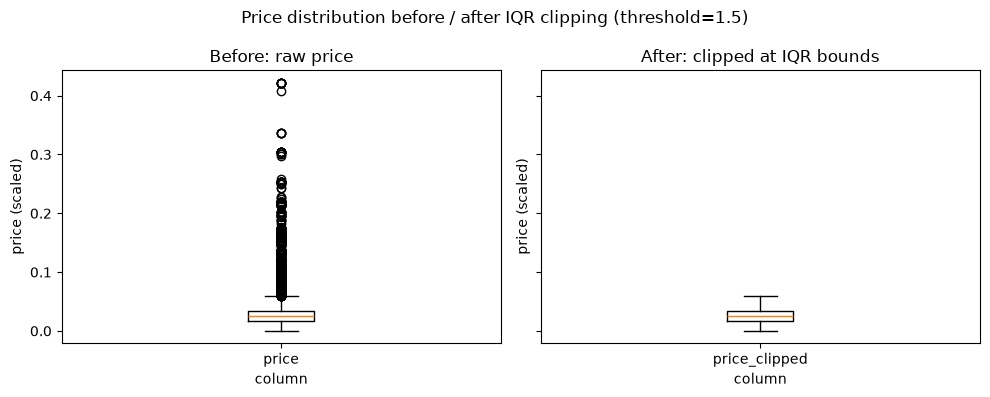

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].boxplot(df["price"], tick_labels=["price"])
axes[0].set_title("Before: raw price")
axes[1].boxplot(df["price_clipped"], tick_labels=["price_clipped"])
axes[1].set_title("After: clipped at IQR bounds")
for ax in axes:
    ax.set_xlabel("column")
    ax.set_ylabel("price (scaled)")
fig.suptitle("Price distribution before / after IQR clipping (threshold=1.5)")
plt.tight_layout()
plt.show()

**해석 — IQR 이상치**

- 경계는 -0.0095 ~ 0.0599 다. 가격에는 음수가 없어 아래쪽 이상치는 0줄이고, 이상치 7,331줄(4.9%)이 **전부 위쪽**이다 → 오른쪽 꼬리.
- 경계값으로 자른 뒤 최댓값 0.4220 → 0.0599, 표준편차 0.0191 → 0.0145(−24%), 평균 0.0280 → 0.0268(−4%). 25%·50%·75% 값은 그대로다 — IQR 방식은 가운데 50% 를 건드리지 않고 꼬리만 누른다.
- **시사점**: 4.9% 의 비싼 구매가 표준편차를 24% 부풀리고 있었다. 평균·표준편차로 가격을 요약하면 이 꼬리에 끌려가므로 중앙값·사분위수를 함께 보고, 실제 구매인 만큼 RFM 의 M 은 원본 `price` 로 계산한다.

## 4. 통계 분석·시각화

`df` 는 거래 줄 단위라서 고객·상품 속성(나이·상품명·사진)은 많이 산 고객, 많이 팔린 상품일수록 여러 번 세어진다. 그래서 통계는 **값이 생기는 단위**에 맞춰 세 표로 나눠 낸다.

| 단위 | 표 | 줄 수 | 열 |
|---|---|---|---|
| 거래 줄 | `df` | 149,548 | `price` |
| 고객 | `cust_table` = `customer_table()` | 10,000 | `age`·`n_items`(구매 줄 수 = 산 상품 개수)·`avg_price`(평균 단가) |
| 상품 | `prod_table` = `product_table()` | 27,783 (사진 있는 상품 1,000) | `avg_price`·`n_sold`(판매 줄 수)·상품명 피처·이미지 피처 |

### 4-1. 기술통계 — 평균·중앙값·표준편차·사분위수

In [19]:
cust_table = analyzer.customer_table()
prod_table = analyzer.product_table()
img_table = prod_table.dropna(subset=["img_mean"])  # 사진을 뽑은 상품 1,000개
print("고객:", len(cust_table), "/ 상품:", len(prod_table), "/ 사진 있는 상품:", len(img_table))

# 거래 줄 단위
summary_stats(df, ["price"]).round(4)

고객: 10000 / 상품: 27783 / 사진 있는 상품: 1000


,count,mean,std,min,q1,median,q3,max
price,149548.0,0.028,0.0191,0.0004,0.0165,0.0254,0.0339,0.422


In [20]:
# 고객 단위 (고객 1명 = 1표)
summary_stats(cust_table, ["age", "n_items", "avg_price"]).round(4)

,count,mean,std,min,q1,median,q3,max
age,10000.0,35.7252,14.4120,17.0000,24.0000,30.0000,48.0000,99.000
n_items,10000.0,14.9548,21.9433,1.0000,3.0000,8.0000,18.0000,462.000
avg_price,10000.0,0.0294,0.0151,0.0024,0.0212,0.0267,0.0339,0.422


In [21]:
# 상품 단위 (상품 1개 = 1표). img_* 는 사진 있는 상품만 값이 있어 count 가 1,000 이다
summary_stats(prod_table, ["avg_price", "n_sold", "prod_name_length", "prod_name_word_count", "img_mean", "img_std"]).round(4)

,count,mean,std,min,q1,median,q3,max
avg_price,27783.0,0.0300,0.0232,0.0004,0.0159,0.0249,0.0372,0.4220
n_sold,27783.0,5.3827,8.5614,1.0000,1.0000,3.0000,6.0000,280.0000
prod_name_length,27783.0,15.7761,5.8080,1.0000,12.0000,15.0000,20.0000,30.0000
prod_name_word_count,27783.0,2.7949,1.0415,1.0000,2.0000,3.0000,3.0000,7.0000
img_mean,1000.0,170.0946,43.3826,22.5338,135.3683,176.5171,208.3424,234.2161
img_std,1000.0,61.5986,29.3071,3.7098,35.6059,67.8146,88.2100,115.8367


**해석 — 기술통계**

- 거래 줄 `price` 는 평균 0.0280 이 중앙값 0.0254 보다 크다. 3장에서 본 오른쪽 꼬리(최댓값 0.422) 때문이다.
- 고객 1만 명의 `n_items`(산 상품 개수)는 중앙값 8개, 평균 15.0개, 최댓값 462개다. 평균이 Q3(18개)에 가까울 만큼 소수 고객이 많이 산다.
- 상품 27,783개의 `n_sold` 는 Q1 이 1이다. 표본에서 팔린 상품의 4분의 1 이상이 딱 한 줄만 팔렸다(중앙값 3, 최댓값 280).
- `age` 는 중앙값 30, 평균 35.7 로 평균이 5.7살 높다. 이유는 4-2 에서 본다.
- **시사점**: 구매 개수와 판매 수 모두 평균이 중앙값의 약 2배다(15.0 vs 8, 5.4 vs 3). "평균 고객"이나 "평균 상품"은 실제 대표값이 아니므로, 고객과 상품은 중앙값·사분위수로 요약한다.

### 4-2. 분포 — 고객 나이 히스토그램

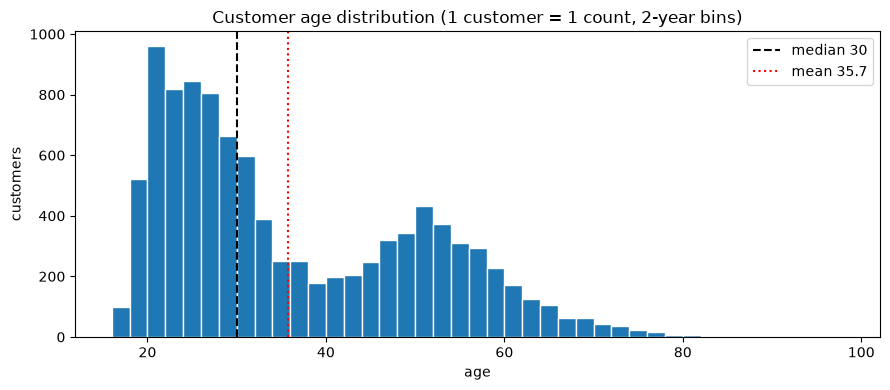

In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(cust_table["age"], bins=np.arange(16, 100, 2), edgecolor="white")
ax.axvline(cust_table["age"].median(), color="black", linestyle="--", label=f"median {cust_table['age'].median():.0f}")
ax.axvline(cust_table["age"].mean(), color="red", linestyle=":", label=f"mean {cust_table['age'].mean():.1f}")
ax.set_title("Customer age distribution (1 customer = 1 count, 2-year bins)")
ax.set_xlabel("age")
ax.set_ylabel("customers")
ax.legend()
plt.tight_layout()
plt.show()

In [23]:
# 히스토그램의 봉우리·골짜기를 숫자로 — 40세 앞뒤 각각에서 고객이 가장 많은 2살 구간
age_bins = pd.cut(cust_table["age"], np.arange(16, 102, 2), right=False)
young = cust_table["age"] < 40
for name, mask in [("40세 미만", young), ("40세 이상", ~young)]:
    counts = age_bins[mask].value_counts()
    print(f"{name} 최다 구간: {counts.idxmax()} → {counts.max()}명")
print("40세 미만 비중(%):", round(young.mean() * 100, 1))
print("35~44세(평균 35.7 근처) 고객 수:", cust_table["age"].between(34, 44, inclusive="right").sum())

40세 미만 최다 구간: [20, 22) → 961명
40세 이상 최다 구간: [50, 52) → 433명
40세 미만 비중(%): 63.8
35~44세(평균 35.7 근처) 고객 수: 1062


**해석 — 나이 분포**

- 봉우리가 두 개다. 20~22세 구간이 961명으로 가장 많고, 40세 이상에서는 50~52세 구간이 433명으로 가장 많다. 40세 미만이 63.8% 다.
- 평균 35.7세 근처인 35~44세는 1,062명으로 오히려 **골짜기**다. 25~34세(3,000명)의 약 3분의 1이다.
- **시사점**: 고객을 "평균 35.7세"로 요약하면 실제로는 고객이 적은 나이대를 대표값으로 잡게 된다. 20대 중심 집단과 50대 중심 집단으로 나눠 봐야 하고, RFM 세그먼트를 해석할 때도 두 집단을 나눠 볼 필요가 있다.

### 4-3. 범주 빈도 — 상위 분류(`index_group_name`) 막대그래프

판매(거래 줄) 비중만 보면 상품 종류가 많은 분류가 크게 보이는 것과 구분할 수 없어, 표본에서 팔린 **상품 종류 수** 비중을 나란히 둔다.

In [24]:
rows = df["index_group_name"].value_counts()
kinds = prod_table["index_group_name"].value_counts()
group_share = pd.DataFrame({
    "transactions_%": rows / rows.sum() * 100,
    "products_%": kinds / kinds.sum() * 100,
    "rows_per_product": rows / kinds,  # 상품 1종당 판매 줄 수
}).sort_values("transactions_%", ascending=False)
group_share.round(1)

,transactions_%,products_%,rows_per_product
index_group_name,,,
Ladieswear,65.7,55.9,6.3
Divided,22.2,21.7,5.5
Menswear,5.9,10.7,3.0
Sport,4.3,3.5,6.6
Baby/Children,2.0,8.2,1.3


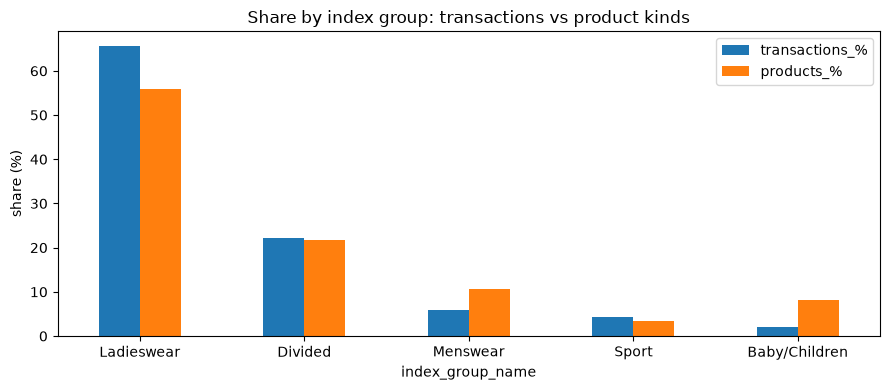

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
group_share[["transactions_%", "products_%"]].plot.bar(ax=ax, rot=0)
ax.set_title("Share by index group: transactions vs product kinds")
ax.set_xlabel("index_group_name")
ax.set_ylabel("share (%)")
plt.tight_layout()
plt.show()

**해석 — 상위 분류 빈도**

- 판매(거래 줄)의 65.7% 가 Ladieswear, 22.2% 가 Divided 로, 두 분류가 87.9% 를 차지한다.
- 상품 종류 비중(표본에서 한 번 이상 팔린 상품 기준)과 견주면 차이가 난다. Baby/Children 은 상품 종류가 8.2% 인데 판매는 2.0% 이고, 상품 1종당 판매가 1.3줄로 Ladieswear(6.3줄)의 약 5분의 1이다. Menswear 도 상품 종류 10.7% 에 판매 5.9% 다.
- **시사점**: 판매가 여성복 두 분류에 몰려 있으므로, 이 표본의 고객 행동(RFM 포함)은 여성복 구매 패턴이 좌우한다. 아동복·남성복은 여러 종류가 조금씩 팔리는 구조라 품목별 판매 회전을 따로 봐야 한다.

### 4-4. 상관 분석 — 상관계수·히트맵·산점도

상관계수는 피어슨(Pearson) 상관계수 r 이다(−1~1, 두 값이 직선으로 같이 움직이는 정도). 쌍마다 값이 생기는 단위에 맞춘 표에서 계산한다.

In [26]:
corr = pd.concat([
    correlation_pairs(img_table, [("img_mean", "avg_price")]).assign(unit="product (with photo)"),
    correlation_pairs(cust_table, [("age", "n_items"), ("age", "avg_price")]).assign(unit="customer"),
], ignore_index=True)
corr.round(3)

,x,y,n,r,unit
0,img_mean,avg_price,1000,-0.227,product (with photo)
1,age,n_items,10000,-0.009,customer
2,age,avg_price,10000,0.132,customer


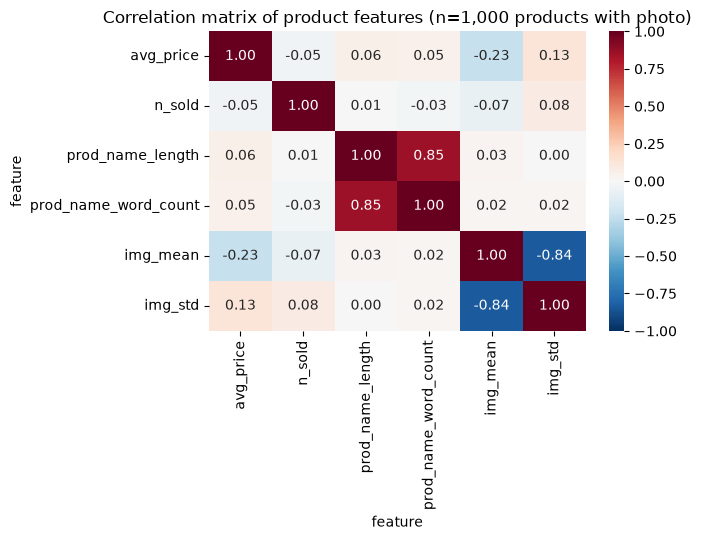

In [27]:
# 상품 단위 수치 열 전체의 상관행렬 — 모든 칸이 같은 상품 1,000개에서 계산되도록 사진 있는 상품만 쓴다
matrix_cols = ["avg_price", "n_sold", "prod_name_length", "prod_name_word_count", "img_mean", "img_std"]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(img_table[matrix_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix of product features (n=1,000 products with photo)")
ax.set_xlabel("feature")
ax.set_ylabel("feature")
plt.tight_layout()
plt.show()

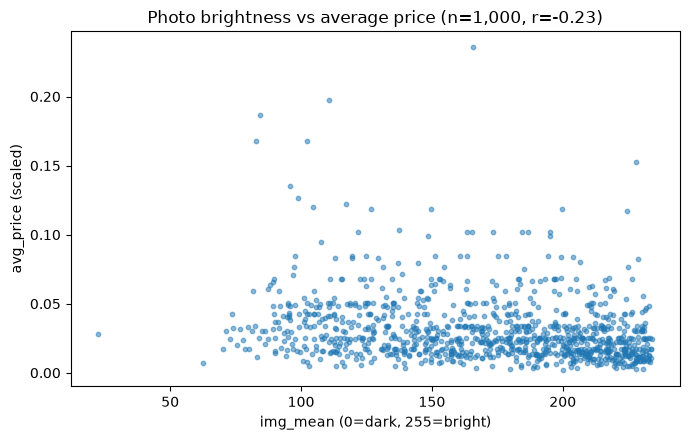

In [28]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(img_table["img_mean"], img_table["avg_price"], s=10, alpha=0.5)
ax.set_title(f"Photo brightness vs average price (n=1,000, r={corr.loc[0, 'r']:.2f})")
ax.set_xlabel("img_mean (0=dark, 255=bright)")
ax.set_ylabel("avg_price (scaled)")
plt.tight_layout()
plt.show()

In [29]:
# 상관계수 하나로는 관계의 모양을 알 수 없어 구간별 중앙값을 같이 본다 (중앙값이라 극단값에 덜 흔들린다)
brightness = pd.qcut(img_table["img_mean"], 4, labels=["Q1 (dark)", "Q2", "Q3", "Q4 (bright)"])
img_table.groupby(brightness, observed=True)["avg_price"].agg(["size", "median"]).round(4)

,size,median
img_mean,,
Q1 (dark),250,0.0330
Q2,250,0.0252
Q3,250,0.0244
Q4 (bright),250,0.0175


In [30]:
# 품목 차이를 뺀 상관 — 밝기·가격에서 '자기 품목 평균'을 빼 품목 안에서의 차이만 남기고 다시 상관을 본다
within = img_table[["img_mean", "avg_price"]] - img_table.groupby("garment_group_name")[["img_mean", "avg_price"]].transform("mean")
r_all = img_table["img_mean"].corr(img_table["avg_price"])
print(f"전체 r = {r_all:.3f}, r² = {r_all ** 2:.3f}")
print(f"같은 품목 안에서의 r = {within['img_mean'].corr(within['avg_price']):.3f} (품목 {img_table['garment_group_name'].nunique()}개)")
(img_table.groupby("garment_group_name")
    .agg(n=("avg_price", "size"), img_mean_median=("img_mean", "median"), avg_price_median=("avg_price", "median"))
    .query("n >= 20").sort_values("img_mean_median").round(4))

전체 r = -0.227, r² = 0.052
같은 품목 안에서의 r = -0.088 (품목 21개)


,n,img_mean_median,avg_price_median
garment_group_name,,,
Outdoor,45,136.9866,0.0678
Unknown,24,143.5596,0.0339
Dresses Ladies,74,144.0285,0.0309
Trousers,64,150.6180,0.0423
Trousers Denim,35,151.2457,0.0424
Shorts,22,159.3808,0.0250
Skirts,28,168.4901,0.0349
Jersey Fancy,191,168.7186,0.0220
Knitwear,71,175.3546,0.0330


In [31]:
age_band = pd.cut(cust_table["age"], [0, 24, 34, 44, 54, 64, 120],
                  labels=["~24", "25-34", "35-44", "45-54", "55-64", "65+"])
cust_table.groupby(age_band, observed=True).agg(
    customers=("age", "size"),
    n_items_median=("n_items", "median"),
    avg_price_median=("avg_price", "median"),
).round(4)

,customers,n_items_median,avg_price_median
age,,,
~24,2834,7.0,0.0251
25-34,3000,9.0,0.0267
35-44,1062,7.0,0.0263
45-54,1782,8.0,0.0277
55-64,1018,6.0,0.0296
65+,304,4.0,0.0305


**해석 — 상관 분석**

- `img_mean` ↔ 상품 평균 가격은 **r = −0.23**(상품 1,000개)으로 약한 음의 관계다. 밝기 4등분 가격 중앙값이 0.0330(가장 어두움)에서 0.0175(가장 밝음)로 47% 낮아지므로, 극단값 몇 개가 만든 관계는 아니다.
- 그러나 r² = 0.05 로, 밝기로 설명되는 가격 차이는 5% 뿐이다. **같은 품목끼리만 비교하면 r = −0.09** 로 거의 사라진다(`garment_group_name` 21개 품목 안에서의 상관). 외투(Outdoor)는 사진이 어둡고(밝기 중앙값 137) 비싸며(0.0678), 액세서리는 밝고(215) 싸다(0.0135). 품목이 밝기와 가격을 함께 정한 결과다.
- `age` ↔ 고객 평균 단가는 **r = 0.13**(고객 1만 명)으로 약한 양의 관계다. 나이대별 중앙값이 ~24세 0.0251 에서 65세 이상 0.0305 로 22% 높다.
- `age` ↔ 구매 개수는 **r = −0.01** 로 직선 관계가 없다. 나이대별 중앙값도 7·9·7·8·6·4개로 오르내리고, 65세 이상(304명)만 4개로 적다.
- 히트맵에서 상품명 길이↔단어 수(0.85)와 `img_mean`↔`img_std`(−0.84)는 같은 성질을 두 번 잰 쌍이다. 상품명 피처와 가격·판매 수의 상관은 |r| ≤ 0.06 으로 거의 없다.
- **시사점**: 모든 쌍이 |r| < 0.3 이다. 가장 큰 밝기↔가격 관계도 품목 차이(교란 변수, confounding variable)를 빼면 −0.09 로 줄어든다. 상관계수만 보고 "어두운 색이 비싸다"고 결론 내리면 안 되고, 가격은 같은 품목 안에서 비교해야 한다.

### 4-5. 추세 — 월별 매출 라인차트

기간의 첫 달(2019-09, 23~30일)과 마지막 달(2020-09, 1~22일)은 한 달을 다 채우지 못해 빼고, 완전한 11개월(2019-10 ~ 2020-08)만 그린다.

t_dat
2019-10    362.5
2019-11    397.6
2019-12    326.9
2020-01    281.5
2020-02    280.1
2020-03    296.2
2020-04    362.6
2020-05    369.5
2020-06    419.7
2020-07    328.5
2020-08    357.8
Freq: M


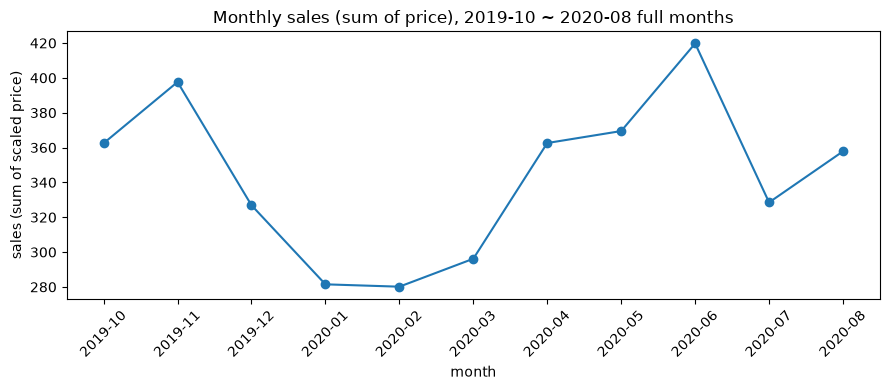

In [32]:
monthly = analyzer.monthly_sales()  # full_months_only=True
print(monthly.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index.astype(str), monthly.values, marker="o")
ax.set_title("Monthly sales (sum of price), 2019-10 ~ 2020-08 full months")
ax.set_xlabel("month")
ax.set_ylabel("sales (sum of scaled price)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**해석 — 월별 매출**

- 11개월 중 최저는 2020-02(280.1), 최고는 2020-06(419.7)으로 1.5배 차이다. 2020-01~03 은 280~296 으로 낮고, 4월(362.6)부터 다시 오른다. 2019-11(397.6)도 높다.
- 같은 고객 1만 명의 구매인데도 월 매출이 최대 50% 달라진다.
- **시사점**: 캠페인 효과를 월 매출로 비교하려면 이 계절 폭(최대 1.5배)을 먼저 감안해야 한다. 다만 데이터가 1년치라, 매년 반복되는 계절성인지 2020년 봄의 일회성 사건인지는 이 데이터만으로 가릴 수 없다.